<a href="https://colab.research.google.com/github/yasminasouki/DataAnalysis/blob/dev/06_cluster_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
PROJ = '/content/drive/MyDrive/pneumonia-project'
IN   = f'{PROJ}/results_05'
OUT  = f'{PROJ}/results_06'
os.makedirs(f'{OUT}/figures', exist_ok=True)

cl = pd.read_csv(f'{IN}/clusters.csv')
print(cl.shape)
print(cl.head())

Mounted at /content/drive
(8999, 12)
                              patientId  real_patient_id  split         class  \
0  0ecd37a6-c1bb-40cf-8e48-1020140ae173            16184  train  Lung Opacity   
1  5ea7521b-b287-4ddd-ac55-14e05c75d62e            10531  train  Lung Opacity   
2  722ad9c3-919a-4c08-bb67-cafd603ba754             3528  train  Lung Opacity   
3  ff3258f3-2c66-40cf-9d5d-fe77f8036fa6             8745  train  Lung Opacity   
4  d6195cb9-e8c5-488a-b406-a43e2ec44af8            21070  train  Lung Opacity   

  view  age sex  target        PC1       PC2  cluster_k2  cluster_k3  
0   AP   43   F       1 -15.294627 -3.425028           1           0  
1   AP   28   F       1  -4.367223  7.972244           1           0  
2   AP   46   M       1 -11.524770 -3.681091           1           0  
3   AP   46   M       1  -8.246772  8.532652           1           0  
4   AP   32   M       1  -2.130222  6.856471           1           0  


In [2]:
for k in ['cluster_k2', 'cluster_k3']:
    print(f'\n========== {k} ==========')
    for col in ['class', 'view', 'sex']:
        t = pd.crosstab(cl[k], cl[col], normalize='index').mul(100).round(1)
        t['X-rays'] = cl[k].value_counts().sort_index()
        print(f'\n% of each {col} inside each cluster:')
        print(t)
    print('\n% pneumonia per cluster:')
    print(cl.groupby(k)['target'].mean().mul(100).round(1))
    print('\nAge per cluster (impossible ages removed):')
    print(cl[cl['age'] <= 100].groupby(k)['age'].agg(['median', 'mean']).round(1))


========== cluster_k2 ==========

% of each class inside each cluster:
class       Lung Opacity  No Lung Opacity / Not Normal  Normal  X-rays
cluster_k2                                                            
0                   17.0                          32.6    50.4    5526
1                   53.1                          37.6     9.3    3473

% of each view inside each cluster:
view          AP    PA  X-rays
cluster_k2                    
0           10.6  89.4    5526
1           88.1  11.9    3473

% of each sex inside each cluster:
sex            F     M  X-rays
cluster_k2                    
0           43.2  56.8    5526
1           43.6  56.4    3473

% pneumonia per cluster:
cluster_k2
0    17.0
1    53.1
Name: target, dtype: float64

Age per cluster (impossible ages removed):
            median  mean
cluster_k2              
0             49.0  47.6
1             50.0  47.5

========== cluster_k3 ==========

% of each class inside each cluster:
class       Lung Opac

In [3]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

rows = []
for k in ['cluster_k2', 'cluster_k3']:
    for col in ['class', 'target', 'view', 'sex']:
        rows.append({'clustering': k, 'compared with': col,
                     'ARI': adjusted_rand_score(cl[col], cl[k]),
                     'NMI': normalized_mutual_info_score(cl[col], cl[k])})
match = pd.DataFrame(rows).round(3)
match.to_csv(f'{OUT}/cluster_match_scores.csv', index=False)
print(match)

   clustering compared with    ARI    NMI
0  cluster_k2         class  0.138  0.134
1  cluster_k2        target  0.177  0.111
2  cluster_k2          view  0.605  0.487
3  cluster_k2           sex  0.000  0.000
4  cluster_k3         class  0.103  0.105
5  cluster_k3        target  0.078  0.081
6  cluster_k3          view  0.406  0.421
7  cluster_k3           sex  0.000  0.000


In [4]:
print("% pneumonia overall per view:")
print(cl.groupby('view')['target'].mean().mul(100).round(1))
for k in ['cluster_k2', 'cluster_k3']:
    t = cl.groupby(['view', k])['target'].agg(['mean', 'count'])
    t['mean'] = (t['mean'] * 100).round(1)
    print(f'\n{k}: % pneumonia inside each view')
    print(t.rename(columns={'mean': '% pneumonia', 'count': 'X-rays'}))

% pneumonia overall per view:
view
AP    50.6
PA    17.6
Name: target, dtype: float64

cluster_k2: % pneumonia inside each view
                 % pneumonia  X-rays
view cluster_k2                     
AP   0                  25.2     583
     1                  55.4    3059
PA   0                  16.1    4943
     1                  35.5     414

cluster_k3: % pneumonia inside each view
                 % pneumonia  X-rays
view cluster_k3                     
AP   0                  56.4    2843
     1                  31.7     640
     2                  22.6     159
PA   0                  43.1     130
     1                  14.7    2369
     2                  18.8    2858


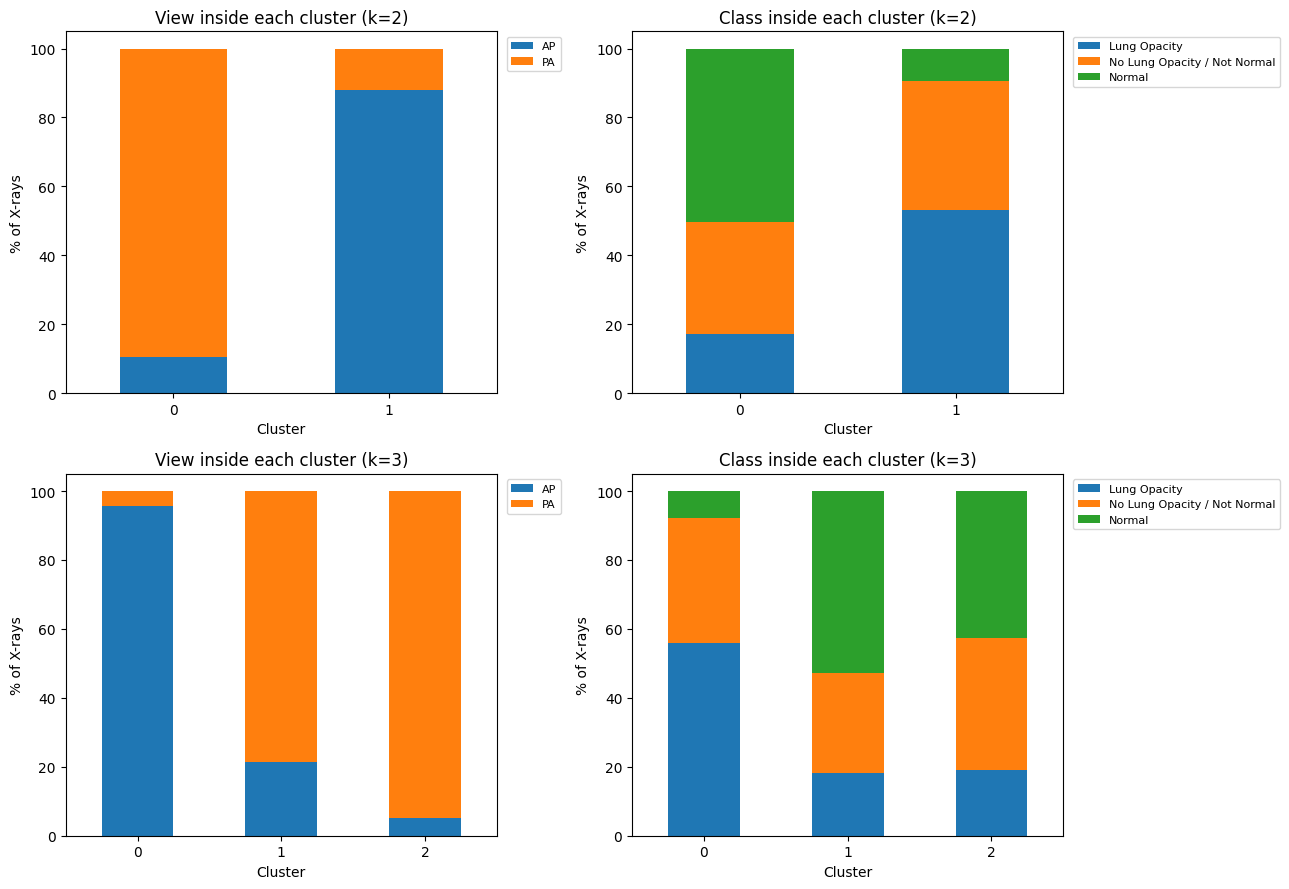

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for r, k in enumerate(['cluster_k2', 'cluster_k3']):
    for c, col in enumerate(['view', 'class']):
        t = pd.crosstab(cl[k], cl[col], normalize='index').mul(100)
        t.plot.bar(stacked=True, ax=axes[r, c], rot=0)
        axes[r, c].set_title(f'{col.capitalize()} inside each cluster (k={k[-1]})')
        axes[r, c].set_xlabel('Cluster'); axes[r, c].set_ylabel('% of X-rays')
        axes[r, c].legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.savefig(f'{OUT}/figures/06_cluster_composition.png', dpi=300, bbox_inches='tight')
plt.show()

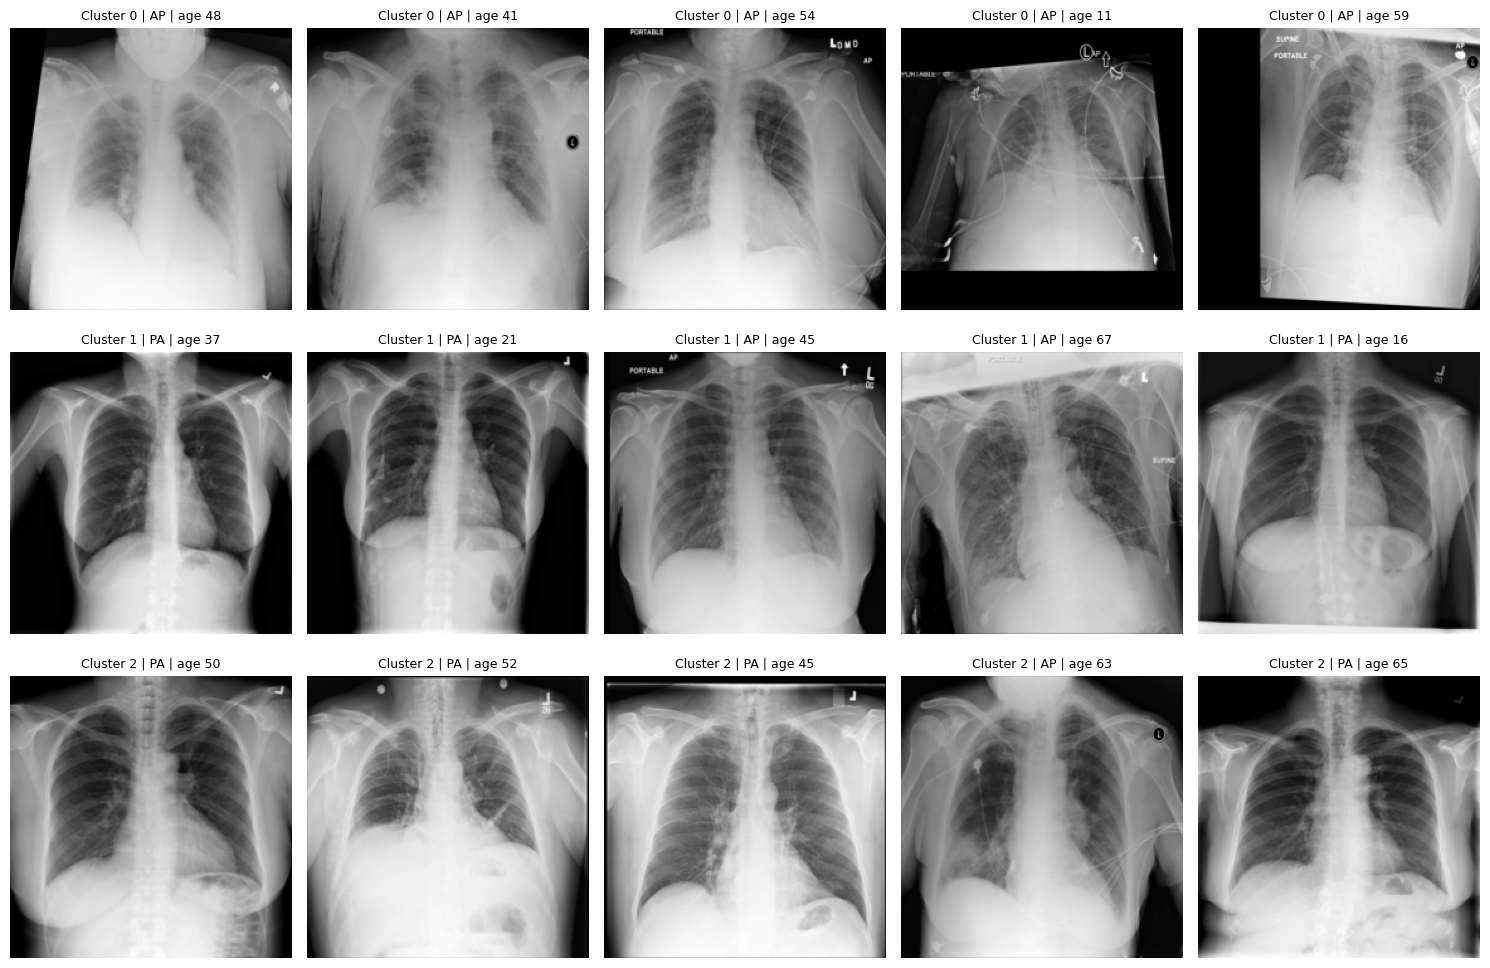

In [6]:
images = np.load(f'{PROJ}/images_224.npz', allow_pickle=True)['images']

fig, axes = plt.subplots(3, 5, figsize=(15, 10))
for c in range(3):
    idx = cl[cl['cluster_k3'] == c].sample(5, random_state=42).index
    for ax, i in zip(axes[c], idx):
        ax.imshow(images[i], cmap='gray'); ax.axis('off')
        ax.set_title(f"Cluster {c} | {cl.loc[i, 'view']} | age {cl.loc[i, 'age']}", fontsize=9)
plt.tight_layout()
plt.savefig(f'{OUT}/figures/06_cluster_examples.png', dpi=300, bbox_inches='tight')
plt.show()